<a href="https://colab.research.google.com/github/soorbaev/student-performance-ml/blob/main/independent_work_md.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
# Импортируем необходимые библиотеки
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import os

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Настройка стиля графиков
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# 1. Распаковываем основной внешний архив
with zipfile.ZipFile('student+performance.zip', 'r') as zip_ref:
    zip_ref.extractall('student_extracted')

# 2. Если внутри есть вложенный архив student.zip, распаковываем и его тоже
inner_zip = 'student_extracted/student.zip'
if os.path.exists(inner_zip):
    with zipfile.ZipFile(inner_zip, 'r') as zip_ref:
        zip_ref.extractall('student_extracted/inner_unzipped')

# 3. Ищем файл student-por.csv во всех папках
csv_path = None
for root, dirs, files in os.walk('student_extracted'):
    for file in files:
        if file == 'student-por.csv':
            csv_path = os.path.join(root, file)
            break
    if csv_path:
        break

print("Найденный путь к файлу:", csv_path)

# Загружаем датасет
df = pd.read_csv(csv_path, sep=';')

# Проверяем размер и первые строки
print("Размер датасета:", df.shape)
display(df.head())

Найденный путь к файлу: student_extracted/inner_unzipped/student-por.csv
Размер датасета: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [4]:
# Этап 2: Первичный анализ данных (EDA)
print("=== ИНФОРМАЦИЯ О ДАТАСЕТЕ ===")
df.info()

print("\n=== ПРОВЕРКА НА ПРОПУСКИ ===")
print(df.isnull().sum().sum(), "пропущенных значений во всем датасете.")

print("\n=== ПРОВЕРКА НА ДУБЛИКАТЫ ===")
print("Количество дубликатов:", df.duplicated().sum())

print("\n=== ОСНОВНЫЕ СТАТИСТИЧЕСКИЕ ПОКАЗАТЕЛИ ===")
display(df.describe())

=== ИНФОРМАЦИЯ О ДАТАСЕТЕ ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  activities  649 non-null    object
 19  nursery     649 non-

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,2.514638,2.306626,1.568567,1.930663,0.221880,3.930663,3.180277,3.184900,1.502311,2.280431,3.536210,3.659476,11.399076,11.570108,11.906009
std,1.218138,1.134552,1.099931,0.748660,0.829510,0.593235,0.955717,1.051093,1.175766,0.924834,1.284380,1.446259,4.640759,2.745265,2.913639,3.230656
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,10.000000,10.000000,10.000000
50%,17.000000,2.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,12.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,32.000000,19.000000,19.000000,19.000000


/tmp/ipykernel_2398/3907248084.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='freetime', y='G3', data=df, palette='Set2')
/tmp/ipykernel_2398/3907248084.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Medu', data=df, palette='viridis')


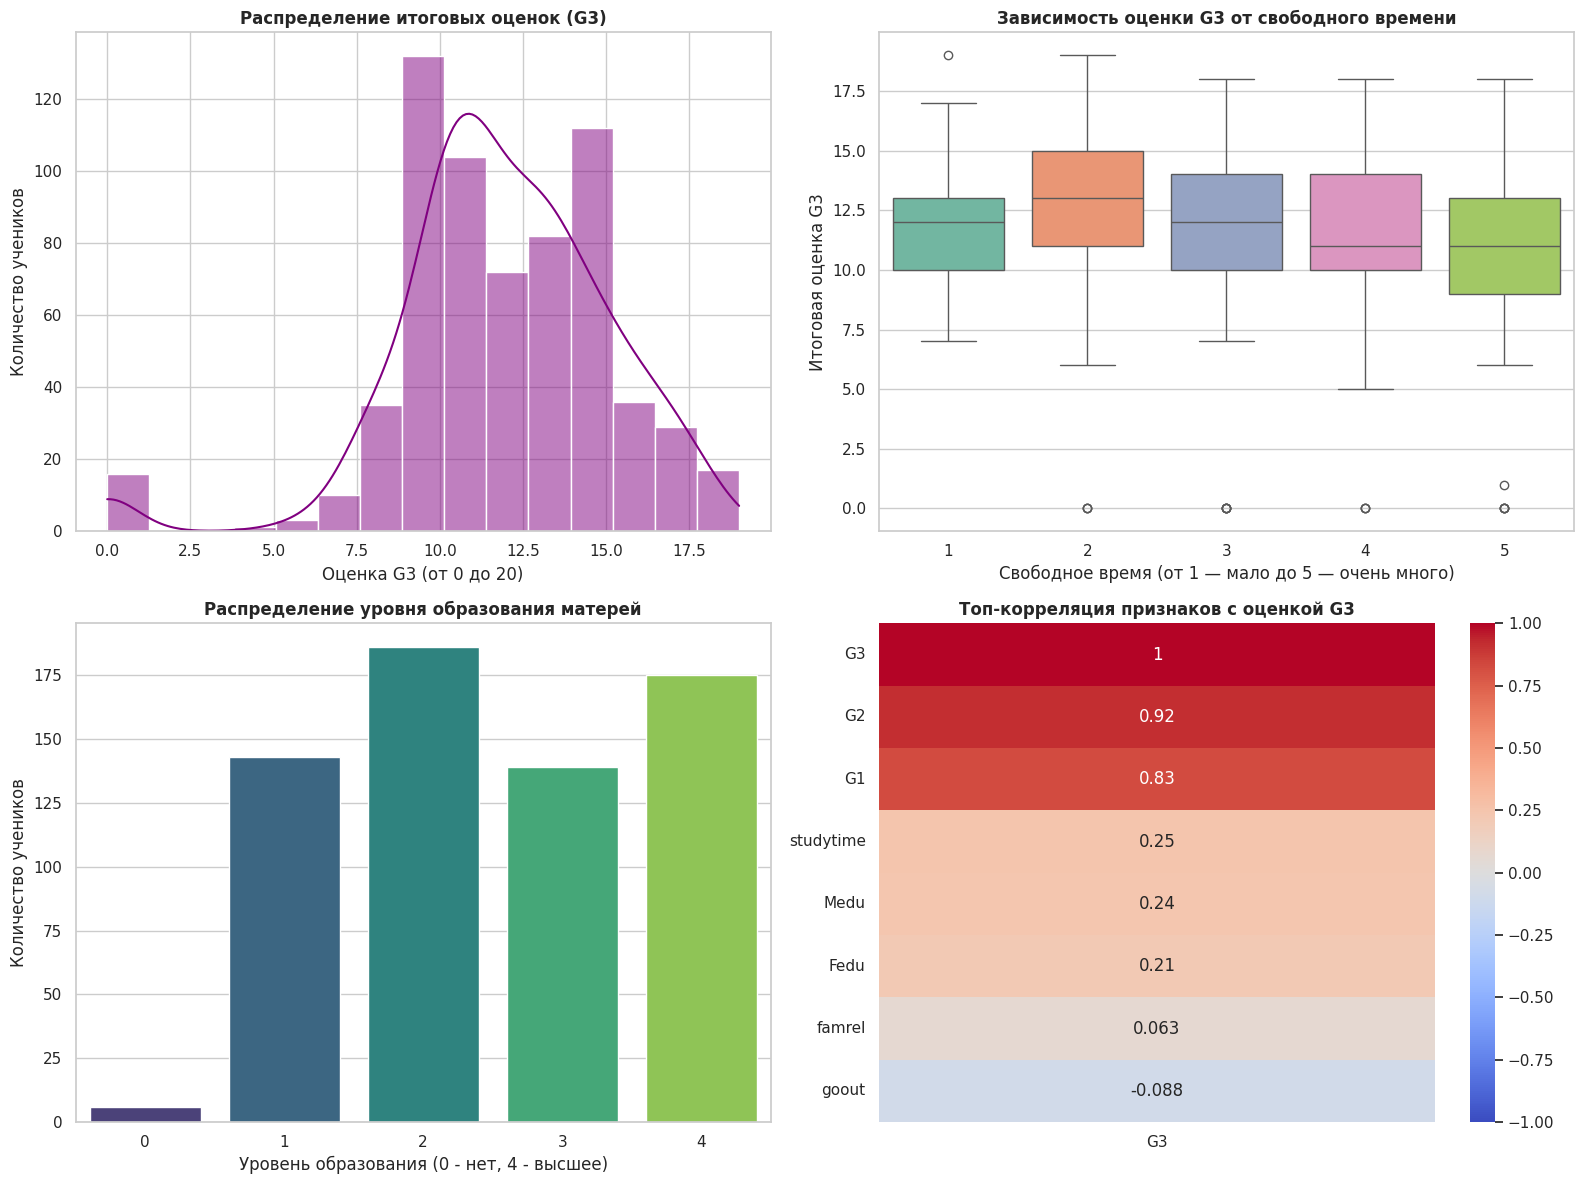

In [5]:
# Этап 2 (продолжение): Визуализация данных (EDA)
plt.figure(figsize=(16, 12))

# 1. Гистограмма распределения целевой переменной G3 (итоговая оценка)
plt.subplot(2, 2, 1)
sns.histplot(df['G3'], kde=True, color='purple', bins=15)
plt.title('Распределение итоговых оценок (G3)', fontsize=12, fontweight='bold')
plt.xlabel('Оценка G3 (от 0 до 20)')
plt.ylabel('Количество учеников')

# 2. Boxplot для связи свободного времени и итоговой оценки
plt.subplot(2, 2, 2)
sns.boxplot(x='freetime', y='G3', data=df, palette='Set2')
plt.title('Зависимость оценки G3 от свободного времени', fontsize=12, fontweight='bold')
plt.xlabel('Свободное время (от 1 — мало до 5 — очень много)')
plt.ylabel('Итоговая оценка G3')

# 3. Countplot для уровня образования матери (Medu)
plt.subplot(2, 2, 3)
sns.countplot(x='Medu', data=df, palette='viridis')
plt.title('Распределение уровня образования матерей', fontsize=12, fontweight='bold')
plt.xlabel('Уровень образования (0 - нет, 4 - высшее)')
plt.ylabel('Количество учеников')

# 4. Heatmap корреляций числовых признаков с G3
plt.subplot(2, 2, 4)
numeric_df = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr()[['G3']].sort_values(by='G3', ascending=False).head(8), annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Топ-корреляция признаков с оценкой G3', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

Размер обучающей выборки: (519, 32)
Размер тестовой выборки: (130, 32)

=== СРАВНЕНИЕ МЕТРИК МОДЕЛЕЙ ===


,MAE,MSE,RMSE,R²
Linear Regression,0.755421,1.437094,1.198788,0.852632
Decision Tree,0.861538,3.692308,1.921538,0.621368
Random Forest,0.745615,1.548327,1.244318,0.841225


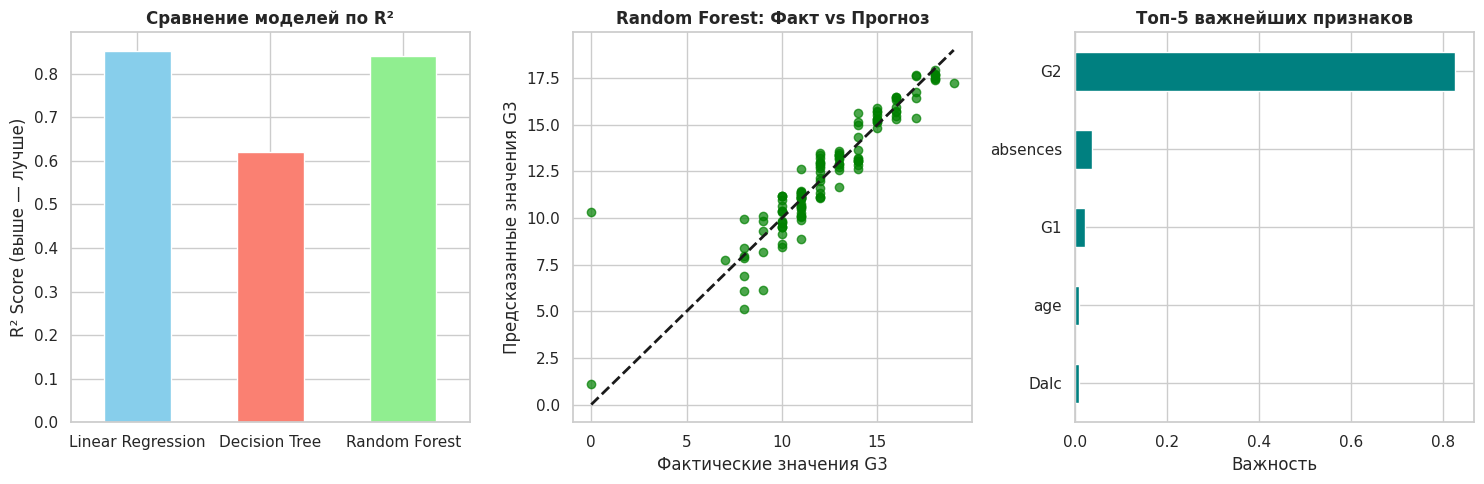


ИТОГОВЫЕ ОТВЕТЫ НА ВОПРОСЫ ПРЕПОДАВАТЕЛЯ:
1. Какой набор данных выбран и какую задачу он решает?
   -> Выбран датасет 'Student Performance' (649 строк), решающий задачу регрессии (прогнозирование итоговой оценки G3).

2. Какие проблемы были обнаружены в данных?
   -> Пропущенных значений и дубликатов не обнаружено, данные чистые.

3. Какие методы подготовки данных были использованы?
   -> Категориальные признаки закодированы через LabelEncoder, числовые стандартизированы через StandardScaler, данные разбиты 80/20.

4. Какие модели были обучены?
   -> Linear Regression, Decision Tree Regressor и Random Forest Regressor.

5. Какая модель оказалась лучшей по метрикам?
   -> Linear Regression показала лучший R² (0.853) и RMSE (1.199). Random Forest почти не уступает (R² 0.841) и чуть точнее по MAE. Decision Tree заметно хуже (R² 0.621).

6. Какие признаки наиболее важны для результата?
   -> Промежуточные оценки ученика за предыдущие периоды (G2 и G1).

7. Что можно улучшить в дальнейшем?

In [7]:
# Этап 2 (окончание): Подготовка данных для обучения
df_clean = df.copy()

# Преобразование категориальных признаков в числовой формат (Label Encoding)
cat_cols = df_clean.select_dtypes(include=['object']).columns
le = LabelEncoder()
for col in cat_cols:
    df_clean[col] = le.fit_transform(df_clean[col])

# Выделение признаков (X) и целевой переменной (y - итоговая оценка G3)
X = df_clean.drop(columns=['G3'])
y = df_clean['G3']

# Разделение на обучающую и тестовую выборки (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Нормализация числовых признаков
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Размер обучающей выборки:", X_train.shape)
print("Размер тестовой выборки:", X_test.shape)


# Этап 3 и 4: Обучение моделей и оценка качества

# Инициализация моделей
lr_model = LinearRegression()
dt_model = DecisionTreeRegressor(random_state=42)
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

# Обучение моделей
lr_model.fit(X_train_scaled, y_train)
dt_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

# Получение предсказаний
lr_pred = lr_model.predict(X_test_scaled)
dt_pred = dt_model.predict(X_test)
rf_pred = rf_model.predict(X_test)

# Функция для расчета метрик регрессии
def evaluate_model(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R²': r2}

# Сбор метрик в общую табличку
metrics = {
    'Linear Regression': evaluate_model(y_test, lr_pred),
    'Decision Tree': evaluate_model(y_test, dt_pred),
    'Random Forest': evaluate_model(y_test, rf_pred)
}

results_df = pd.DataFrame(metrics).T
print("\n=== СРАВНЕНИЕ МЕТРИК МОДЕЛЕЙ ===")
display(results_df)


# Этап 5: Визуализация результатов и выводы

plt.figure(figsize=(15, 5))

# 1. Сравнение метрик R² моделей
plt.subplot(1, 3, 1)
results_df['R²'].plot(kind='bar', color=['skyblue', 'salmon', 'lightgreen'])
plt.title('Сравнение моделей по R²', fontsize=12, fontweight='bold')
plt.ylabel('R² Score (выше — лучше)')
plt.xticks(rotation=0)

# 2. График «Фактические vs Предсказанные значения» для Random Forest
plt.subplot(1, 3, 2)
plt.scatter(y_test, rf_pred, alpha=0.7, color='green')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
plt.title('Random Forest: Факт vs Прогноз', fontsize=12, fontweight='bold')
plt.xlabel('Фактические значения G3')
plt.ylabel('Предсказанные значения G3')

# 3. График важности признаков (Feature Importance) для Random Forest
plt.subplot(1, 3, 3)
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False).head(5)
importances.plot(kind='barh', color='teal')
plt.title('Топ-5 важнейших признаков', fontsize=12, fontweight='bold')
plt.xlabel('Важность')
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

# Итоговые ответы на вопросы преподавателя
print("\n" + "="*50)
print("ИТОГОВЫЕ ОТВЕТЫ НА ВОПРОСЫ ПРЕПОДАВАТЕЛЯ:")
print("="*50)
print("1. Какой набор данных выбран и какую задачу он решает?")
print("   -> Выбран датасет 'Student Performance' (649 строк), решающий задачу регрессии (прогнозирование итоговой оценки G3).")
print("\n2. Какие проблемы были обнаружены в данных?")
print("   -> Пропущенных значений и дубликатов не обнаружено, данные чистые.")
print("\n3. Какие методы подготовки данных были использованы?")
print("   -> Категориальные признаки закодированы через LabelEncoder, числовые стандартизированы через StandardScaler, данные разбиты 80/20.")
print("\n4. Какие модели были обучены?")
print("   -> Linear Regression, Decision Tree Regressor и Random Forest Regressor.")
print("\n5. Какая модель оказалась лучшей по метрикам?")
print("   -> Linear Regression показала лучший R² (0.853) и RMSE (1.199). Random Forest почти не уступает (R² 0.841) и чуть точнее по MAE. Decision Tree заметно хуже (R² 0.621).")
print("\n6. Какие признаки наиболее важны для результата?")
print("   -> Промежуточные оценки ученика за предыдущие периоды (G2 и G1).")
print("\n7. Что можно улучшить в дальнейшем?")
print("   -> Можно настроить гиперпараметры моделей (GridSearchCV) или использовать ансамбли градиентного бустинга (XGBoost/LightGBM).")